# 02 · Open one annotated slide

I want to check that I can read a whole-slide image on the Mac and place its supplied tumor outline correctly.

This first example is `patient_092_node_1.tif`, labeled `macro`, from hospital 4. It is the smallest slide in the saved inventory with that label and an XML annotation, about 875 MB. The larger lesion should be easier to see in a thumbnail. This choice is for checking the code, so it does not represent the whole dataset.

The first download is much larger than the metadata download in notebook 01. Later runs verify and reuse the same local files.


In [2]:
from pathlib import Path
from importlib.metadata import version
from datetime import datetime, timezone
import json
import platform
import sys
import xml.etree.ElementTree as ET

import matplotlib.pyplot as plt
from matplotlib.patches import Polygon, Patch
import numpy as np
import openslide
import pandas as pd
from PIL import ImageCms
from IPython.display import display

ROOT = next(
    folder for folder in (Path.cwd(), *Path.cwd().parents)
    if (folder / "src" / "fetch_camelyon17_sample.py").is_file()
)
sys.path.insert(0, str(ROOT / "src"))
from fetch_camelyon17_sample import fetch_sample


## 1. Download the image and annotation

The downloader fetches one TIFF image and its matching XML file. It compares their sizes with the saved file list and checks both published MD5 hashes. It only gives a download its final filename after those checks pass.

The files stay under `data/raw/camelyon17/`, which is excluded from Git. A failed download can be retried by running this cell again; an incomplete file starts over.


In [3]:
sample = fetch_sample()
image_path = sample["files"]["image"]["path"]
annotation_path = sample["files"]["annotation"]["path"]
OUT = ROOT / "data" / "derived" / "camelyon17" / "slide_inspection" / image_path.stem
OUT.mkdir(parents=True, exist_ok=True)

display(pd.DataFrame([
    {"file": details["path"].name, "stored_MB": details["bytes"] / 1e6,
     "published_MD5": details["md5"], "check": "passed"}
    for details in sample["files"].values()
]))


Using the verified local metadata snapshot.
Verified local patient_092_node_1.xml.
Verified local patient_092_node_1.tif.


,file,stored_MB,published_MD5,check
0,patient_092_node_1.xml,0.031964,7873d05592e22849d9277b8ca49cb6a0,passed
1,patient_092_node_1.tif,875.466460,6f1b46a69fde3782594df0937aecfd88,passed


## 2. Read the resolution information

Level 0 is the full-resolution image. The other levels are smaller versions of the same image, which let us view it without decoding every full-resolution pixel.

The pixel size, in micrometers per pixel, tells us how much physical distance one pixel covers. Objective magnification is a separate metadata field. Missing values stay marked as "not recorded."

This cell also reads a thumbnail with a maximum width or height of 1,400 pixels. If the image has an embedded color profile, it converts the thumbnail to sRGB for display.


In [4]:
with openslide.OpenSlide(image_path) as slide:
    width, height = slide.dimensions
    properties = dict(slide.properties)
    mpp_x = properties.get(openslide.PROPERTY_NAME_MPP_X)
    mpp_y = properties.get(openslide.PROPERTY_NAME_MPP_Y)
    metadata = {
        "slide_id": sample["slide_id"],
        "hospital": sample["hospital"],
        "label": sample["label"],
        "format": properties.get(openslide.PROPERTY_NAME_VENDOR),
        "width_px": width,
        "height_px": height,
        "gigapixels": width * height / 1e9,
        "resolution_levels": slide.level_count,
        "micrometers_per_pixel_x": float(mpp_x) if mpp_x is not None else None,
        "micrometers_per_pixel_y": float(mpp_y) if mpp_y is not None else None,
        "objective_magnification": properties.get(openslide.PROPERTY_NAME_OBJECTIVE_POWER),
        "has_color_profile": slide.color_profile is not None,
    }
    levels = pd.DataFrame([
        {"level": level, "width_px": size[0], "height_px": size[1],
         "downsample": slide.level_downsamples[level]}
        for level, size in enumerate(slide.level_dimensions)
    ])
    thumbnail = slide.get_thumbnail((1400, 1400))
    if slide.color_profile is not None:
        thumbnail = ImageCms.profileToProfile(
            thumbnail, slide.color_profile, ImageCms.createProfile("sRGB"),
            renderingIntent=ImageCms.getDefaultIntent(slide.color_profile),
            outputMode="RGB",
        )

display(pd.Series(metadata, name="value").fillna("not recorded").to_frame())


,value
slide_id,patient_092_node_1.tif
hospital,4
label,macro
format,philips
width_px,184320
height_px,93696
gigapixels,17.270047
resolution_levels,10
micrometers_per_pixel_x,0.25
micrometers_per_pixel_y,0.25


In [5]:
display(levels)


,level,width_px,height_px,downsample
0,0,184320,93696,1.0
1,1,92160,46848,2.0
2,2,46080,23424,4.0
3,3,23040,11712,8.0
4,4,11520,5856,16.0
5,5,5760,2928,32.0
6,6,2880,1464,64.0
7,7,1440,732,128.0
8,8,720,366,256.0
9,9,360,183,512.0


## 3. Read the tumor outlines

The XML stores polygons as ordered X and Y coordinates at full resolution. Each polygon traces an annotated region. The number of polygons is not a count of patients or a separate slide label.

"Tumor" regions mark the supplied tumor areas; "Exclusion" regions, when present, mark areas cut out of them. The code checks that the polygons have valid coordinates inside the image. It stops if it encounters an annotation type or group it does not understand.


In [4]:
xml_root = ET.parse(annotation_path).getroot()
if xml_root.tag != "ASAP_Annotations":
    raise ValueError("Expected an ASAP annotation file.")

polygons = []
for annotation in xml_root.findall("./Annotations/Annotation"):
    group = annotation.get("PartOfGroup")
    if annotation.get("Type") != "Polygon" or group not in {"Tumor", "Exclusion"}:
        raise ValueError("Inspect the unfamiliar annotation type or group before plotting.")
    points = sorted(
        annotation.findall("./Coordinates/Coordinate"),
        key=lambda point: int(point.attrib["Order"]),
    )
    xy = np.array([(float(p.attrib["X"]), float(p.attrib["Y"])) for p in points])
    if len(xy) < 3 or not np.isfinite(xy).all():
        raise ValueError("A polygon has too few points or invalid coordinates.")
    if (xy < 0).any() or (xy[:, 0] > width).any() or (xy[:, 1] > height).any():
        raise ValueError("Annotation coordinates fall outside the full-resolution image.")
    polygons.append({"group": group, "xy": xy})

if not any(polygon["group"] == "Tumor" for polygon in polygons):
    raise ValueError("This example needs at least one tumor polygon.")
annotation_counts = pd.Series(
    [polygon["group"] for polygon in polygons], name="group"
).value_counts().rename("polygons")
display(annotation_counts.to_frame())


,polygons
group,
Tumor,4


## 4. Compare the thumbnail with the supplied annotation

The left panel shows the image on its own. The right adds the XML outlines. These are the published annotations, not model predictions.

The thumbnail is displayed using the full-resolution coordinate range. That lets the polygons use their original coordinates, including Y increasing downward. The image remains a small thumbnail in memory. Small outlines may be difficult to see at this scale.


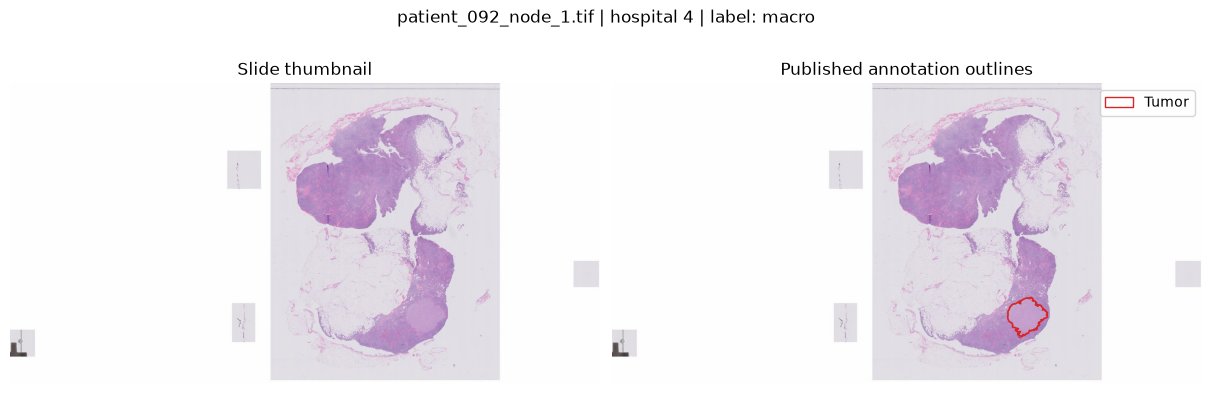

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), layout="constrained")
for axis, title in zip(axes, ("Slide thumbnail", "Published annotation outlines")):
    axis.imshow(thumbnail, extent=(0, width, height, 0), origin="upper")
    axis.set(xlim=(0, width), ylim=(height, 0), title=title)
    axis.set_axis_off()

colors = {"Tumor": "#D62728", "Exclusion": "#00A6B2"}
for polygon in polygons:
    axes[1].add_patch(Polygon(
        polygon["xy"], closed=True, fill=False,
        edgecolor=colors[polygon["group"]], linewidth=1.2,
        linestyle="--" if polygon["group"] == "Exclusion" else "-",
    ))
axes[1].legend(handles=[
    Patch(facecolor="none", edgecolor=colors[group], label=group)
    for group in annotation_counts.index
], loc="upper right")
fig.suptitle(f"{image_path.name} | hospital {sample['hospital']} | label: {sample['label']}")
fig.savefig(OUT / "annotation_overlay.png", dpi=150)
plt.show()


## 5. Save what we inspected

The resolution table, thumbnail, overlay, and inspection summary stay under `data/derived/camelyon17/slide_inspection/`. The summary records the source files and verified hashes so the example can be traced back to the downloaded data.

This completes the first slide inspection. It does not establish how slides from the other hospitals behave. The next part of this step is to inspect two slides per hospital and compare their metadata and thumbnails.


In [6]:
levels.to_csv(OUT / "resolution_levels.csv", index=False)
thumbnail.save(OUT / "thumbnail.png", icc_profile=thumbnail.info.get("icc_profile"))
inspection = {
    "inspected_at_utc": datetime.now(timezone.utc).isoformat(),
    "metadata_snapshot_utc": sample["metadata_retrieved_at_utc"],
    "selection": "Smallest labeled macro slide with XML in the saved inventory.",
    "metadata": metadata,
    "annotation_polygons": {group: int(count) for group, count in annotation_counts.items()},
    "files": {
        kind: {**details, "path": details["path"].relative_to(ROOT).as_posix(),
               "md5_verified": True}
        for kind, details in sample["files"].items()
    },
    "software": {
        "python": platform.python_version(),
        "openslide-python": version("openslide-python"),
        "openslide-library": openslide.__library_version__,
        "pillow": version("pillow"),
        "numpy": version("numpy"),
        "pandas": version("pandas"),
        "matplotlib": version("matplotlib"),
    },
}
(OUT / "inspection_summary.json").write_text(
    json.dumps(inspection, indent=2, allow_nan=False) + "\n", encoding="utf-8"
)
print("Saved inspection outputs under:", OUT.relative_to(ROOT))


Saved inspection outputs under: data/derived/camelyon17/slide_inspection/patient_092_node_1


## Sources

- [CAMELYON on AWS Open Data](https://registry.opendata.aws/camelyon/): source bucket and access information.
- The saved CAMELYON17 README, labels, file list, and published checksums used in notebook 01.
- [CAMELYON17 challenge paper, section II-D](https://geertlitjens.nl/publication/band-18/band-18.pdf): annotation coordinates at the highest image resolution.
- [OpenSlide Python documentation](https://openslide.org/api/python/): resolution levels, pixel-size properties, thumbnails, and color profiles.
